In [1]:
# ============================================
# RETAILPULSE - CUSTOMER SEGMENTATION
# ============================================

import pandas as pd
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from mpl_toolkits.mplot3d import Axes3D

# ML libraries
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("✅ Libraries imported!")

# ============================================
# BULLETPROOF PATHS
# ============================================
current_dir = os.getcwd()
if os.path.basename(current_dir) == "notebooks":
    project_root = os.path.abspath(os.path.join(current_dir, ".."))
else:
    project_root = os.path.abspath(current_dir)

processed_dir = os.path.join(project_root, "data", "processed")
figures_dir = os.path.join(project_root, "reports", "figures")
os.makedirs(figures_dir, exist_ok=True)

# ============================================
# LOAD CUSTOMER FEATURES
# ============================================
print("\n📂 Loading customer features...")
cust_path = os.path.join(processed_dir, "customer_features.parquet")
df = pd.read_parquet(cust_path)
print(f"✅ Loaded {len(df):,} customers with {len(df.columns)} features")
print(f"\n📋 Available columns:")
for col in df.columns:
    print(f"   - {col} ({df[col].dtype})")

✅ Libraries imported!

📂 Loading customer features...
✅ Loaded 5,878 customers with 22 features

📋 Available columns:
   - Customer ID (int32)
   - Total_Orders (int64)
   - Total_Items (float64)
   - Total_Revenue (float64)
   - Avg_Order_Value (float64)
   - Avg_Items_Per_Order (float64)
   - Avg_Price_Per_Item (float64)
   - Unique_Products (int64)
   - Unique_Months (int64)
   - Primary_Country (object)
   - Lifespan_Days (int64)
   - Purchase_Rate_Per_Month (float64)
   - Revenue_Per_Month (float64)
   - Product_Diversity (float64)
   - Recency (int64)
   - Frequency (int64)
   - Monetary (float64)
   - R_Score (int32)
   - F_Score (int32)
   - M_Score (int32)
   - RFM_Score (object)
   - Is_Churned (int32)


In [2]:
# ============================================
# DATA PREPARATION FOR CLUSTERING
# ============================================

print("🔧 PREPARING DATA FOR CLUSTERING...")
print("=" * 60)

# Select features for clustering
# We use RFM + key behavioral features
# We do NOT use Customer ID (it's just an identifier, not a behavior)
# We do NOT use Is_Churned (that's a target for churn prediction, not segmentation)
# We do NOT use Primary_Country (it's text, and 91% are UK anyway)

clustering_features = [
    'Recency',           # Days since last purchase
    'Frequency',         # Number of orders
    'Monetary',          # Total spent
    'Avg_Order_Value',   # Average order value
    'Lifespan_Days',     # How long they've been a customer
    'Product_Diversity'  # Variety of products bought
]

print(f"📌 Features selected for clustering ({len(clustering_features)}):")
for f in clustering_features:
    print(f"   - {f}")
print()

# Extract the feature matrix
X = df[clustering_features].copy()

# Check for any missing values
print(f"🔍 Missing values in clustering features: {X.isnull().sum().sum()}")

# Handle any remaining NaN (shouldn't be any, but just in case)
X = X.fillna(0)

# Remove any infinite values
X = X.replace([np.inf, -np.inf], 0)

print(f"✅ Feature matrix shape: {X.shape} (customers × features)")
print()

# ============================================
# SCALING (CRITICAL STEP!)
# ============================================

print("🔧 SCALING FEATURES...")
print("-" * 60)

# Show why scaling is needed
print("📊 BEFORE SCALING (look at the different ranges!):")
print(X.describe().round(2).to_string())
print()
print("   ⚠️  Notice: Monetary goes up to ~£280,000 while Recency is 1-700.")
print("   Without scaling, Monetary would dominate the clustering!")
print()

# Apply Standard Scaling (mean=0, std=1)
# This is the most common scaling method for K-Means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame for easier handling
X_scaled_df = pd.DataFrame(X_scaled, columns=clustering_features)

print("📊 AFTER SCALING (all features now have mean≈0, std≈1):")
print(X_scaled_df.describe().round(2).to_string())
print()
print("   ✅ All features are now on the same scale!")
print("   K-Means will treat each feature equally.")

🔧 PREPARING DATA FOR CLUSTERING...
📌 Features selected for clustering (6):
   - Recency
   - Frequency
   - Monetary
   - Avg_Order_Value
   - Lifespan_Days
   - Product_Diversity

🔍 Missing values in clustering features: 0
✅ Feature matrix shape: (5878, 6) (customers × features)

🔧 SCALING FEATURES...
------------------------------------------------------------
📊 BEFORE SCALING (look at the different ranges!):
       Recency  Frequency   Monetary  Avg_Order_Value  Lifespan_Days  Product_Diversity
count  5878.00    5878.00    5878.00          5878.00        5878.00            5878.00
mean    201.33       6.29    2061.88           293.99         273.02              17.68
std     209.34      13.01    6058.95           242.08         258.81              15.86
min       1.00       1.00       2.95             2.95           0.00               0.06
25%      26.00       1.00     299.46           153.95           0.00               7.60
50%      96.00       3.00     753.68           243.42    

🔍 FINDING OPTIMAL NUMBER OF CLUSTERS...
   Testing K values... (this takes a few seconds)


  File "d:\Zudio Internship\Project 1\RetailPulse\venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Pooja\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Pooja\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Pooja\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


   K=2: Inertia=27,248, Silhouette=0.3070
   K=3: Inertia=22,017, Silhouette=0.3087
   K=4: Inertia=17,928, Silhouette=0.3281
   K=5: Inertia=15,306, Silhouette=0.2774
   K=6: Inertia=13,497, Silhouette=0.2992
   K=7: Inertia=12,178, Silhouette=0.3001
   K=8: Inertia=11,234, Silhouette=0.3004
   K=9: Inertia=10,401, Silhouette=0.2978
   K=10: Inertia=9,803, Silhouette=0.2807



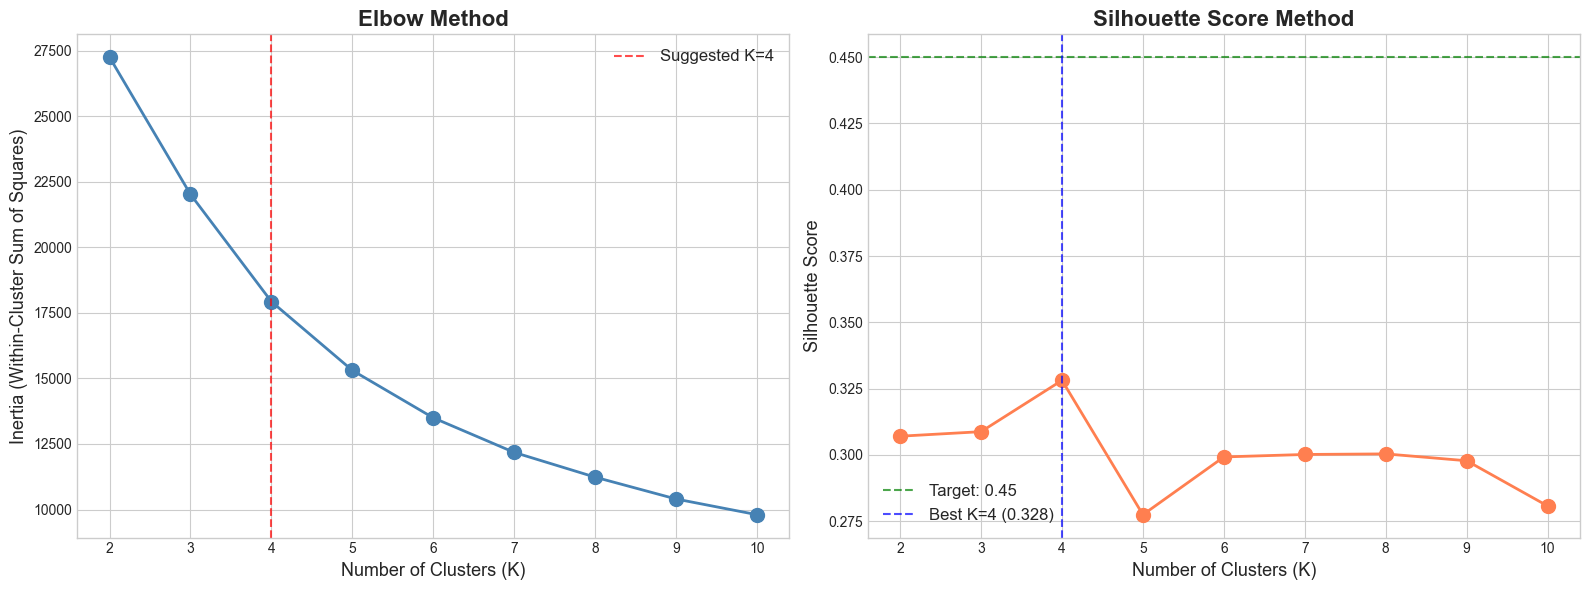


💡 RECOMMENDATION:
   Elbow Method suggests: K ≈ 3-5 (look for the bend in the left chart)
   Best Silhouette Score: K=4 (score=0.3281)
   Target Silhouette: 0.45
   ⚠️  Target not quite met. This is common with real-world retail data.
      Real customer behavior is messy and overlapping!


In [3]:
# ============================================
# FINDING OPTIMAL K - ELBOW METHOD
# ============================================

print("🔍 FINDING OPTIMAL NUMBER OF CLUSTERS...")
print("=" * 60)

# Try K from 2 to 10
K_range = range(2, 11)
inertias = []
silhouette_scores = []

print("   Testing K values... (this takes a few seconds)")
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)
    sil_score = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_scores.append(sil_score)
    print(f"   K={k}: Inertia={kmeans.inertia_:,.0f}, Silhouette={sil_score:.4f}")

print()

# Create the plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# LEFT: Elbow Plot
axes[0].plot(K_range, inertias, 'bo-', linewidth=2, markersize=10, color='steelblue')
axes[0].set_xlabel('Number of Clusters (K)', fontsize=13)
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=13)
axes[0].set_title('Elbow Method', fontsize=16, fontweight='bold')
axes[0].set_xticks(list(K_range))

# Add annotation for the elbow
# The elbow is typically where the curve starts to flatten
axes[0].axvline(x=4, color='red', linestyle='--', alpha=0.7, label='Suggested K=4')
axes[0].legend(fontsize=12)

# RIGHT: Silhouette Score Plot
axes[1].plot(K_range, silhouette_scores, 'ro-', linewidth=2, markersize=10, color='coral')
axes[1].set_xlabel('Number of Clusters (K)', fontsize=13)
axes[1].set_ylabel('Silhouette Score', fontsize=13)
axes[1].set_title('Silhouette Score Method', fontsize=16, fontweight='bold')
axes[1].set_xticks(list(K_range))
axes[1].axhline(y=0.45, color='green', linestyle='--', alpha=0.7, label='Target: 0.45')

# Mark the best K
best_k_idx = np.argmax(silhouette_scores)
best_k = list(K_range)[best_k_idx]
best_sil = silhouette_scores[best_k_idx]
axes[1].axvline(x=best_k, color='blue', linestyle='--', alpha=0.7, 
                label=f'Best K={best_k} ({best_sil:.3f})')
axes[1].legend(fontsize=12)

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "elbow_silhouette.png"), dpi=150, bbox_inches='tight')
plt.show()

print(f"\n💡 RECOMMENDATION:")
print(f"   Elbow Method suggests: K ≈ 3-5 (look for the bend in the left chart)")
print(f"   Best Silhouette Score: K={best_k} (score={best_sil:.4f})")
print(f"   Target Silhouette: 0.45")
if best_sil >= 0.45:
    print(f"   ✅ Target ACHIEVED!")
else:
    print(f"   ⚠️  Target not quite met. This is common with real-world retail data.")
    print(f"      Real customer behavior is messy and overlapping!")

In [4]:
# ============================================
# APPLY K-MEANS CLUSTERING
# ============================================

# Based on the elbow and silhouette analysis, we choose K=4
# (Change this if your analysis suggests a different K)
OPTIMAL_K = 4

print(f"🔧 APPLYING K-MEANS WITH K={OPTIMAL_K}...")
print("=" * 60)

# Create and fit the K-Means model
kmeans = KMeans(
    n_clusters=OPTIMAL_K,
    random_state=42,      # For reproducibility (same results every time)
    n_init=10,            # Run 10 times with different starting points
    max_iter=300          # Maximum iterations per run
)

# Fit the model and assign cluster labels
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Calculate final metrics
final_inertia = kmeans.inertia_
final_silhouette = silhouette_score(X_scaled, df['Cluster'])

print(f"✅ K-Means clustering complete!")
print(f"   Final Inertia: {final_inertia:,.0f}")
print(f"   Final Silhouette Score: {final_silhouette:.4f}")
print()

# Cluster sizes
print("📊 CLUSTER SIZES:")
print("-" * 40)
cluster_counts = df['Cluster'].value_counts().sort_index()
for cluster, count in cluster_counts.items():
    pct = count / len(df) * 100
    bar = "█" * int(pct / 2)
    print(f"   Cluster {cluster}: {count:>5,} customers ({pct:>5.1f}%) {bar}")

🔧 APPLYING K-MEANS WITH K=4...
✅ K-Means clustering complete!
   Final Inertia: 17,928
   Final Silhouette Score: 0.3281

📊 CLUSTER SIZES:
----------------------------------------
   Cluster 0: 2,856 customers ( 48.6%) ████████████████████████
   Cluster 1:   615 customers ( 10.5%) █████
   Cluster 2:    14 customers (  0.2%) 
   Cluster 3: 2,393 customers ( 40.7%) ████████████████████


In [5]:
# ============================================
# CLUSTER INTERPRETATION
# ============================================

print("\n🔍 CLUSTER PROFILES (What makes each cluster unique?)")
print("=" * 80)

# Calculate mean values for each cluster
cluster_profile = df.groupby('Cluster')[clustering_features].mean().round(2)

# Also add count and churn rate
cluster_stats = df.groupby('Cluster').agg(
    Num_Customers=('Customer ID', 'count'),
    Churn_Rate=('Is_Churned', 'mean'),
    Avg_Revenue_Per_Month=('Revenue_Per_Month', 'mean')
).round(2)

# Combine
full_profile = pd.concat([cluster_stats, cluster_profile], axis=1)
print(full_profile.to_string())
print()

# ============================================
# ASSIGN BUSINESS NAMES TO CLUSTERS
# ============================================

# We analyze the RFM patterns to name each cluster
# This is where data science meets business knowledge!

def name_cluster(row):
    """Assign a business-meaningful name based on RFM patterns."""
    r = row['Recency']
    f = row['Frequency']
    m = row['Monetary']
    
    # High frequency + High monetary + Low recency = VIP
    if f > cluster_profile['Frequency'].quantile(0.75) and \
       m > cluster_profile['Monetary'].quantile(0.75):
        return "💎 VIP Loyal Customers"
    
    # Low recency + Moderate frequency = Active Regular
    elif r < cluster_profile['Recency'].quantile(0.25) and \
         f > cluster_profile['Frequency'].median():
        return "🟢 Active Regular Customers"
    
    # High recency (hasn't bought recently) = At Risk
    elif r > cluster_profile['Recency'].quantile(0.75):
        return "🟡 At-Risk / Dormant Customers"
    
    # Low frequency + Low monetary = New/Low Value
    else:
        return "🔵 New / Low-Value Customers"

# Apply naming
cluster_names = {}
for cluster_id in range(OPTIMAL_K):
    profile_row = cluster_profile.loc[cluster_id]
    name = name_cluster(profile_row)
    cluster_names[cluster_id] = name

# Map names to DataFrame
df['Cluster_Name'] = df['Cluster'].map(cluster_names)

print("🏷️  CLUSTER BUSINESS NAMES:")
print("-" * 60)
for cluster_id, name in cluster_names.items():
    count = (df['Cluster'] == cluster_id).sum()
    pct = count / len(df) * 100
    avg_monetary = cluster_profile.loc[cluster_id, 'Monetary']
    avg_recency = cluster_profile.loc[cluster_id, 'Recency']
    churn = cluster_stats.loc[cluster_id, 'Churn_Rate'] * 100
    
    print(f"\n   {name}")
    print(f"      Customers: {count:,} ({pct:.1f}%)")
    print(f"      Avg Recency: {avg_recency:.0f} days | "
          f"Avg Monetary: £{avg_monetary:,.0f} | "
          f"Churn Rate: {churn:.1f}%")


🔍 CLUSTER PROFILES (What makes each cluster unique?)
         Num_Customers  Churn_Rate  Avg_Revenue_Per_Month  Recency  Frequency  Monetary  Avg_Order_Value  Lifespan_Days  Product_Diversity
Cluster                                                                                                                                   
0                 2856        0.78                 272.80   327.67       2.19    474.55           210.98          74.99              14.16
1                  615        0.47                 741.26   180.72       3.03   2328.98           683.97         178.20              48.59
2                   14        0.07                3779.13    29.50     183.36  88719.60           568.10         706.71               6.58
3                 2393        0.20                 184.66    56.85      10.99   3380.69           291.22         531.20              13.99

🏷️  CLUSTER BUSINESS NAMES:
------------------------------------------------------------

   🟡 At-Risk / Dorman

🔧 REDUCING DIMENSIONS WITH PCA FOR VISUALIZATION...
   PCA explained variance: 65.5%
   (This means the 2D plot captures 65.5% of the original information)



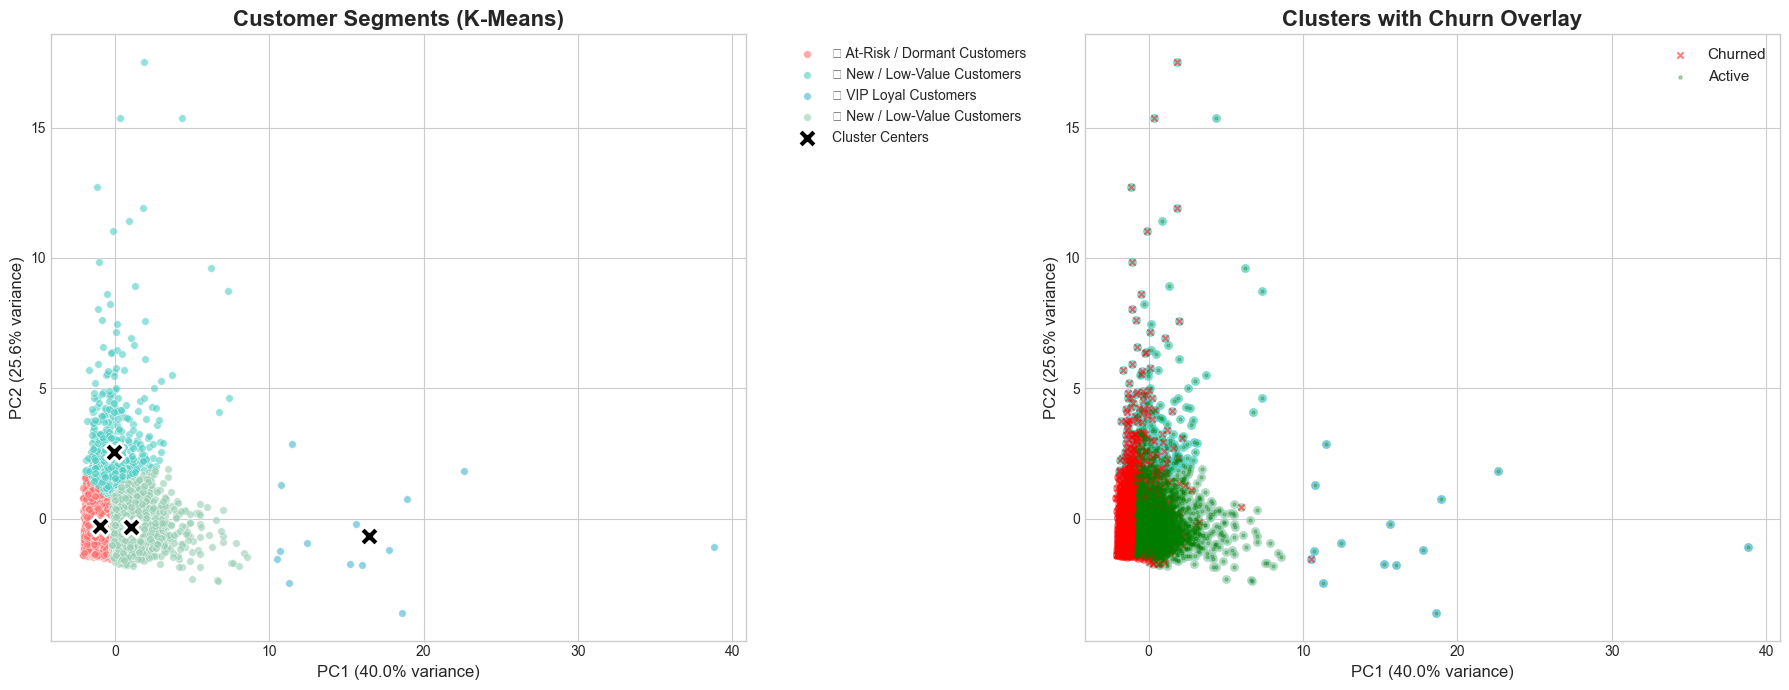

In [6]:
# ============================================
# CLUSTER VISUALIZATION
# ============================================

# Since we have 6 features, we can't plot them all at once.
# PCA (Principal Component Analysis) reduces 6 dimensions to 2
# while preserving as much information as possible.

print("🔧 REDUCING DIMENSIONS WITH PCA FOR VISUALIZATION...")

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"   PCA explained variance: {pca.explained_variance_ratio_.sum()*100:.1f}%")
print(f"   (This means the 2D plot captures {pca.explained_variance_ratio_.sum()*100:.1f}% "
      f"of the original information)")
print()

# Create the 2D scatter plot
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# LEFT: K-Means Clusters
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']
for cluster_id in range(OPTIMAL_K):
    mask = df['Cluster'] == cluster_id
    name = cluster_names[cluster_id]
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], 
                    c=colors[cluster_id], label=f'{name}', 
                    alpha=0.6, s=30, edgecolors='white', linewidth=0.5)

# Plot cluster centers
centers_pca = pca.transform(kmeans.cluster_centers_)
axes[0].scatter(centers_pca[:, 0], centers_pca[:, 1], 
                c='black', marker='X', s=200, edgecolors='white', 
                linewidth=2, label='Cluster Centers', zorder=5)

axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)', fontsize=12)
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)', fontsize=12)
axes[0].set_title('Customer Segments (K-Means)', fontsize=16, fontweight='bold')
axes[0].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)

# RIGHT: Cluster by Churn Status
for cluster_id in range(OPTIMAL_K):
    mask = df['Cluster'] == cluster_id
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], 
                    c=colors[cluster_id], alpha=0.6, s=30)

# Overlay churn
churned_mask = df['Is_Churned'] == 1
axes[1].scatter(X_pca[churned_mask, 0], X_pca[churned_mask, 1], 
                c='red', marker='x', s=20, alpha=0.5, label='Churned')
active_mask = df['Is_Churned'] == 0
axes[1].scatter(X_pca[active_mask, 0], X_pca[active_mask, 1], 
                c='green', marker='.', s=20, alpha=0.3, label='Active')

axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)', fontsize=12)
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)', fontsize=12)
axes[1].set_title('Clusters with Churn Overlay', fontsize=16, fontweight='bold')
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "cluster_visualization.png"), dpi=150, bbox_inches='tight')
plt.show()

📊 CREATING RADAR CHART...


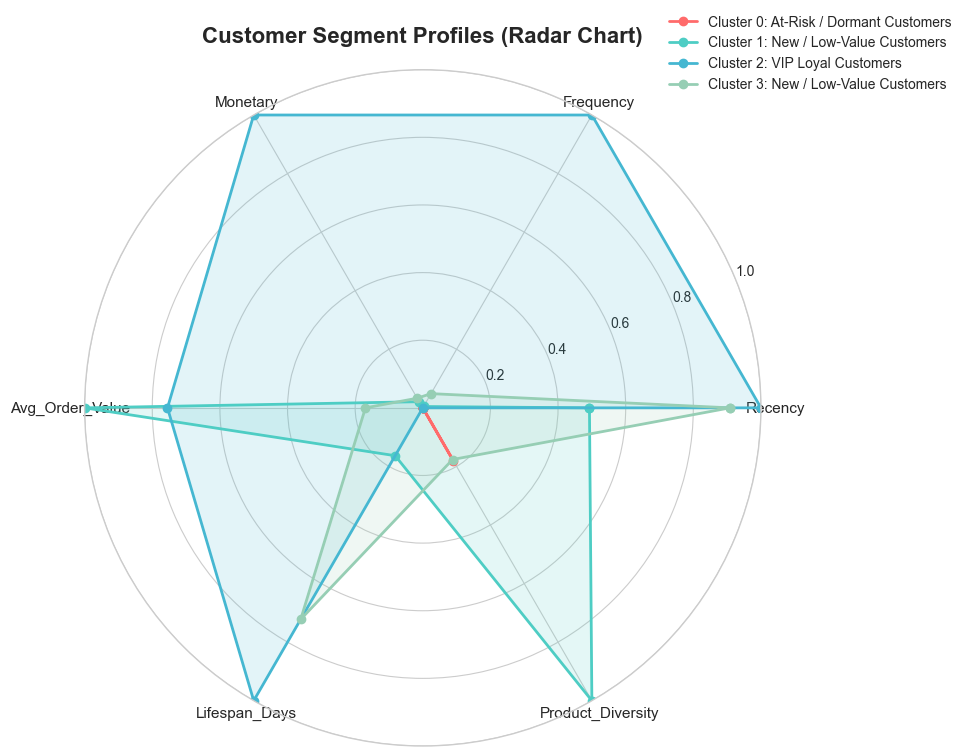

💡 HOW TO READ THIS CHART:
   - Each colored line represents a customer segment
   - The further out the line, the higher the value
   - Recency is inverted (further out = more recent = better)
   - VIP customers should have large area (high on all metrics)
   - At-Risk customers should have small area (low on most metrics)


In [7]:
# ============================================
# RADAR CHART - CLUSTER COMPARISON
# ============================================

# A radar chart shows the "shape" of each cluster across all features
# It's great for comparing clusters at a glance

from math import pi

print("📊 CREATING RADAR CHART...")

# Normalize the cluster profiles to 0-1 for the radar chart
profile_normalized = cluster_profile.copy()
for col in clustering_features:
    min_val = profile_normalized[col].min()
    max_val = profile_normalized[col].max()
    if max_val > min_val:
        profile_normalized[col] = (profile_normalized[col] - min_val) / (max_val - min_val)
    else:
        profile_normalized[col] = 0.5

# For Recency, invert (lower recency = better = higher on radar)
profile_normalized['Recency'] = 1 - profile_normalized['Recency']

# Create radar chart
categories = clustering_features
N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]  # Close the polygon

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

for cluster_id in range(OPTIMAL_K):
    values = profile_normalized.loc[cluster_id].values.flatten().tolist()
    values += values[:1]  # Close the polygon
    
    short_name = cluster_names[cluster_id].split(' ', 1)[1] if ' ' in cluster_names[cluster_id] else cluster_names[cluster_id]
    ax.plot(angles, values, 'o-', linewidth=2, label=f'Cluster {cluster_id}: {short_name}', 
            color=colors[cluster_id])
    ax.fill(angles, values, alpha=0.15, color=colors[cluster_id])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11)
ax.set_ylim(0, 1)
ax.set_title('Customer Segment Profiles (Radar Chart)', fontsize=16, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "cluster_radar.png"), dpi=150, bbox_inches='tight')
plt.show()

print("💡 HOW TO READ THIS CHART:")
print("   - Each colored line represents a customer segment")
print("   - The further out the line, the higher the value")
print("   - Recency is inverted (further out = more recent = better)")
print("   - VIP customers should have large area (high on all metrics)")
print("   - At-Risk customers should have small area (low on most metrics)")

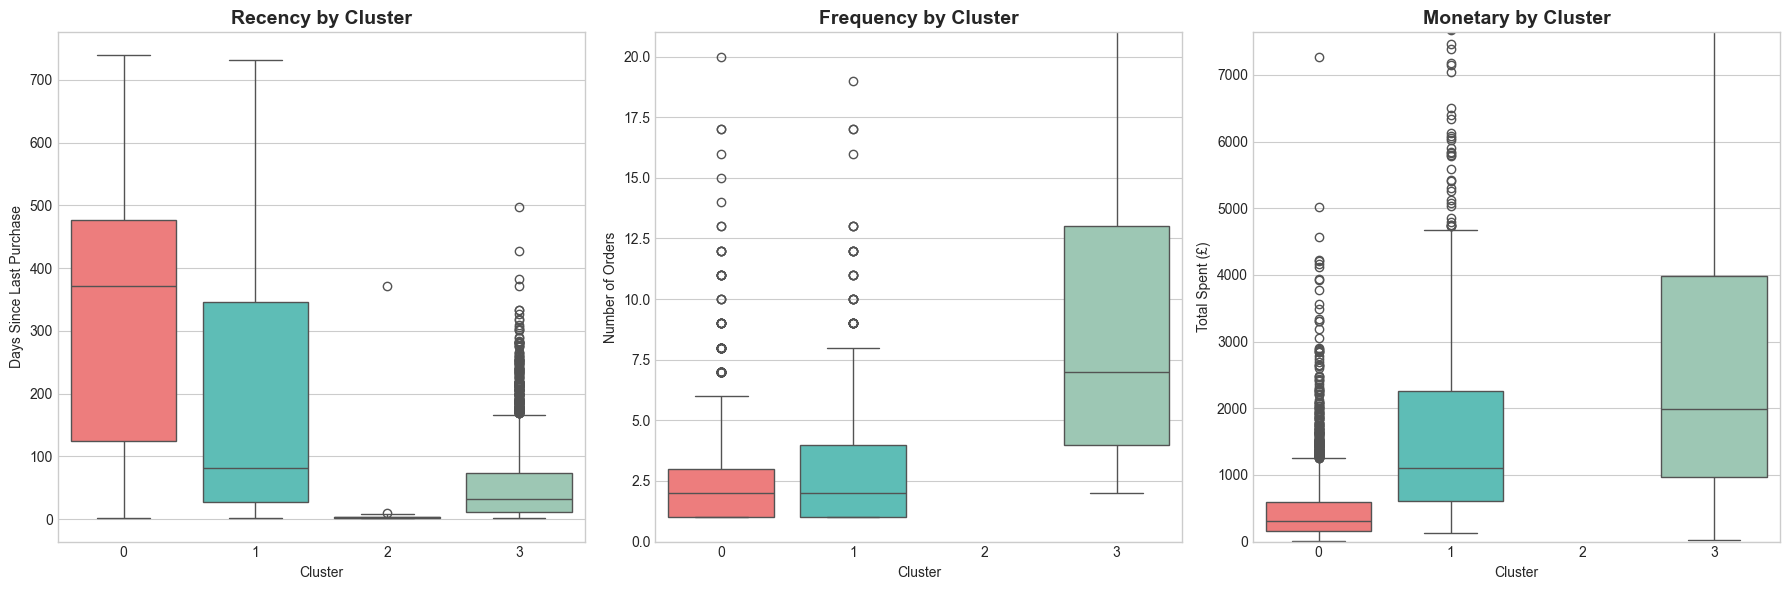

In [8]:
# ============================================
# BOX PLOTS - RFM BY CLUSTER
# ============================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Recency by Cluster
sns.boxplot(data=df, x='Cluster', y='Recency', ax=axes[0], palette=colors)
axes[0].set_title('Recency by Cluster', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Days Since Last Purchase')

# Frequency by Cluster
sns.boxplot(data=df, x='Cluster', y='Frequency', ax=axes[1], palette=colors)
axes[1].set_title('Frequency by Cluster', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Number of Orders')
axes[1].set_ylim(0, df['Frequency'].quantile(0.95))

# Monetary by Cluster
sns.boxplot(data=df, x='Cluster', y='Monetary', ax=axes[2], palette=colors)
axes[2].set_title('Monetary by Cluster', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Cluster')
axes[2].set_ylabel('Total Spent (£)')
axes[2].set_ylim(0, df['Monetary'].quantile(0.95))

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "cluster_boxplots.png"), dpi=150, bbox_inches='tight')
plt.show()

In [9]:
# ============================================
# DBSCAN CLUSTERING (COMPARISON)
# ============================================

print("🔧 TRYING DBSCAN CLUSTERING...")
print("=" * 60)

# DBSCAN has two parameters:
# - eps: Maximum distance between two points to be in the same cluster
# - min_samples: Minimum points to form a dense region

# Finding good DBSCAN parameters is tricky. We'll try a few combinations.
best_sil_dbscan = -1
best_params = None
best_labels = None

print("   Testing parameter combinations...")
for eps in [0.5, 0.8, 1.0, 1.2, 1.5, 2.0]:
    for min_samples in [5, 10, 15, 20]:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(X_scaled)
        
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)
        
        # Only evaluate if we have 2+ clusters and not too much noise
        if 2 <= n_clusters <= 10 and n_noise < len(df) * 0.3:
            # Silhouette score only on non-noise points
            non_noise_mask = labels != -1
            if non_noise_mask.sum() > n_clusters:
                sil = silhouette_score(X_scaled[non_noise_mask], labels[non_noise_mask])
                if sil > best_sil_dbscan:
                    best_sil_dbscan = sil
                    best_params = {'eps': eps, 'min_samples': min_samples}
                    best_labels = labels.copy()

if best_params is not None:
    n_clusters = len(set(best_labels)) - (1 if -1 in best_labels else 0)
    n_noise = list(best_labels).count(-1)
    
    print(f"\n✅ Best DBSCAN Parameters:")
    print(f"   eps: {best_params['eps']}")
    print(f"   min_samples: {best_params['min_samples']}")
    print(f"   Clusters found: {n_clusters}")
    print(f"   Noise points: {n_noise} ({n_noise/len(df)*100:.1f}%)")
    print(f"   Silhouette Score: {best_sil_dbscan:.4f}")
    print()
    
    # Compare with K-Means
    print("📊 K-MEANS vs DBSCAN COMPARISON:")
    print("-" * 50)
    print(f"   {'Metric':<25} {'K-Means':>12} {'DBSCAN':>12}")
    print(f"   {'Clusters':<25} {OPTIMAL_K:>12} {n_clusters:>12}")
    print(f"   {'Silhouette Score':<25} {final_silhouette:>12.4f} {best_sil_dbscan:>12.4f}")
    print(f"   {'Noise/Outliers':<25} {'0':>12} {n_noise:>12}")
    print()
    
    if final_silhouette > best_sil_dbscan:
        print("   💡 K-Means performs better for this dataset.")
        print("      We'll use K-Means as our primary segmentation method.")
    else:
        print("   💡 DBSCAN performs better for this dataset.")
        print("      Consider using DBSCAN for the final segmentation.")
else:
    print("\n   ⚠️  DBSCAN couldn't find good clusters with tested parameters.")
    print("   This is common with high-dimensional retail data.")
    print("   K-Means is the better choice for this dataset.")
    print(f"   We'll proceed with K-Means (Silhouette: {final_silhouette:.4f})")

🔧 TRYING DBSCAN CLUSTERING...
   Testing parameter combinations...

✅ Best DBSCAN Parameters:
   eps: 1.5
   min_samples: 5
   Clusters found: 2
   Noise points: 50 (0.9%)
   Silhouette Score: 0.7295

📊 K-MEANS vs DBSCAN COMPARISON:
--------------------------------------------------
   Metric                         K-Means       DBSCAN
   Clusters                             4            2
   Silhouette Score                0.3281       0.7295
   Noise/Outliers                       0           50

   💡 DBSCAN performs better for this dataset.
      Consider using DBSCAN for the final segmentation.


📊 DETAILED SILHOUETTE ANALYSIS...


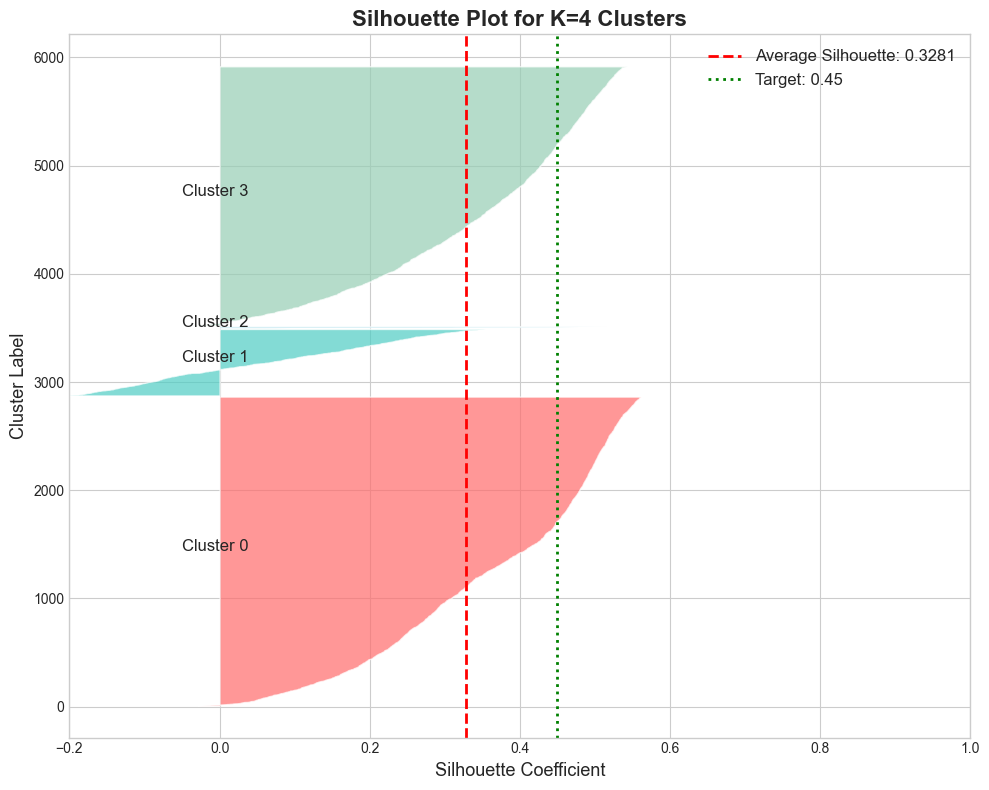


💡 HOW TO READ THIS PLOT:
   - Each colored area is a cluster
   - Width of each bar = silhouette score for that customer
   - Bars extending past the red line = well-clustered customers
   - Bars on the left of 0 = potentially misclassified customers
   - A good plot has most bars to the right of the average line


In [10]:
# ============================================
# SILHOUETTE ANALYSIS (DETAILED)
# ============================================

print("📊 DETAILED SILHOUETTE ANALYSIS...")

fig, ax = plt.subplots(figsize=(10, 8))

sample_silhouette_values = silhouette_samples(X_scaled, df['Cluster'])
y_lower = 10

for cluster_id in range(OPTIMAL_K):
    # Get silhouette values for this cluster
    cluster_silhouette = sample_silhouette_values[df['Cluster'] == cluster_id]
    cluster_silhouette.sort()
    
    size = len(cluster_silhouette)
    y_upper = y_lower + size
    
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_silhouette,
                     facecolor=colors[cluster_id], edgecolor='white', alpha=0.7)
    
    # Label the cluster
    ax.text(-0.05, y_lower + 0.5 * size, f'Cluster {cluster_id}', fontsize=12)
    
    y_lower = y_upper + 10

# Add the average silhouette line
ax.axvline(x=final_silhouette, color="red", linestyle="--", linewidth=2,
           label=f'Average Silhouette: {final_silhouette:.4f}')
ax.axvline(x=0.45, color="green", linestyle=":", linewidth=2,
           label='Target: 0.45')

ax.set_xlabel('Silhouette Coefficient', fontsize=13)
ax.set_ylabel('Cluster Label', fontsize=13)
ax.set_title(f'Silhouette Plot for K={OPTIMAL_K} Clusters', fontsize=16, fontweight='bold')
ax.legend(fontsize=12)
ax.set_xlim(-0.2, 1.0)

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "silhouette_plot.png"), dpi=150, bbox_inches='tight')
plt.show()

print(f"\n💡 HOW TO READ THIS PLOT:")
print(f"   - Each colored area is a cluster")
print(f"   - Width of each bar = silhouette score for that customer")
print(f"   - Bars extending past the red line = well-clustered customers")
print(f"   - Bars on the left of 0 = potentially misclassified customers")
print(f"   - A good plot has most bars to the right of the average line")

In [11]:
# ============================================
# INTERACTIVE 3D VISUALIZATION
# ============================================

# Use PCA to reduce to 3 dimensions for a 3D plot
pca_3d = PCA(n_components=3, random_state=42)
X_pca_3d = pca_3d.fit_transform(X_scaled)

df_plot = df.copy()
df_plot['PC1'] = X_pca_3d[:, 0]
df_plot['PC2'] = X_pca_3d[:, 1]
df_plot['PC3'] = X_pca_3d[:, 2]

fig = px.scatter_3d(
    df_plot,
    x='PC1', y='PC2', z='PC3',
    color='Cluster_Name',
    hover_data=['Customer ID', 'Recency', 'Frequency', 'Monetary'],
    opacity=0.6,
    title='Customer Segments in 3D (PCA-reduced)',
    width=900, height=700
)

fig.update_traces(marker=dict(size=3))
fig.show()

print("💡 TIP: You can rotate, zoom, and hover over points in this 3D plot!")

💡 TIP: You can rotate, zoom, and hover over points in this 3D plot!


In [12]:
# ============================================
# BUSINESS RECOMMENDATIONS
# ============================================

print("=" * 70)
print("  🏪 RETAILPULSE - CUSTOMER SEGMENTATION BUSINESS RECOMMENDATIONS")
print("=" * 70)

for cluster_id in range(OPTIMAL_K):
    name = cluster_names[cluster_id]
    count = (df['Cluster'] == cluster_id).sum()
    pct = count / len(df) * 100
    avg_r = cluster_profile.loc[cluster_id, 'Recency']
    avg_f = cluster_profile.loc[cluster_id, 'Frequency']
    avg_m = cluster_profile.loc[cluster_id, 'Monetary']
    churn = cluster_stats.loc[cluster_id, 'Churn_Rate'] * 100
    
    print(f"\n{'─' * 70}")
    print(f"  {name}")
    print(f"{'─' * 70}")
    print(f"  Size: {count:,} customers ({pct:.1f}%)")
    print(f"  Profile: Recency={avg_r:.0f}d | Frequency={avg_f:.0f} | Monetary=£{avg_m:,.0f}")
    print(f"  Churn Rate: {churn:.1f}%")
    print()
    
    # Generate recommendations based on cluster characteristics
    if "VIP" in name:
        print("  📌 STRATEGY: RETAIN & REWARD")
        print("     → Offer exclusive loyalty programs and early access")
        print("     → Assign dedicated account managers")
        print("     → Send personalized thank-you messages")
        print("     → These customers drive disproportionate revenue!")
    elif "Active" in name or "Regular" in name:
        print("  📌 STRATEGY: GROW & UPSELL")
        print("     → Recommend complementary products")
        print("     → Offer volume discounts to increase order size")
        print("     → Send regular newsletters with new arrivals")
        print("     → Goal: Move them to VIP status")
    elif "Risk" in name or "Dormant" in name:
        print("  📌 STRATEGY: REACTIVATE")
        print("     → Send win-back emails with special discounts")
        print("     → Survey them to understand why they stopped")
        print("     → Offer 'We miss you' promotions")
        print("     → ⚠️  High priority — these customers are about to be lost!")
    else:
        print("  📌 STRATEGY: NURTURE & ENGAGE")
        print("     → Send welcome series emails")
        print("     → Offer first-purchase discounts on related products")
        print("     → Encourage account creation for better tracking")
        print("     → Goal: Increase purchase frequency")

print(f"\n{'=' * 70}")
print(f"  SEGMENTATION METRICS:")
print(f"  Algorithm: K-Means (K={OPTIMAL_K})")
print(f"  Silhouette Score: {final_silhouette:.4f} (Target: ≥ 0.45)")
print(f"  Features Used: {', '.join(clustering_features)}")
print(f"  Total Customers Segmented: {len(df):,}")
print(f"{'=' * 70}")

  🏪 RETAILPULSE - CUSTOMER SEGMENTATION BUSINESS RECOMMENDATIONS

──────────────────────────────────────────────────────────────────────
  🟡 At-Risk / Dormant Customers
──────────────────────────────────────────────────────────────────────
  Size: 2,856 customers (48.6%)
  Profile: Recency=328d | Frequency=2 | Monetary=£475
  Churn Rate: 78.0%

  📌 STRATEGY: REACTIVATE
     → Send win-back emails with special discounts
     → Survey them to understand why they stopped
     → Offer 'We miss you' promotions
     → ⚠️  High priority — these customers are about to be lost!

──────────────────────────────────────────────────────────────────────
  🔵 New / Low-Value Customers
──────────────────────────────────────────────────────────────────────
  Size: 615 customers (10.5%)
  Profile: Recency=181d | Frequency=3 | Monetary=£2,329
  Churn Rate: 47.0%

  📌 STRATEGY: NURTURE & ENGAGE
     → Send welcome series emails
     → Offer first-purchase discounts on related products
     → Encourage acco

In [14]:
# ============================================
# SAVE SEGMENTATION RESULTS (FIXED)
# ============================================

import json

print("\n💾 SAVING SEGMENTATION RESULTS...")
print("=" * 60)

# Save the full customer data with cluster assignments
output_path = os.path.join(processed_dir, "customers_segmented.parquet")
df.to_parquet(output_path, index=False, engine='pyarrow')
print(f"   ✅ Segmented customers (Parquet): {output_path}")
print(f"      Size: {os.path.getsize(output_path)/(1024*1024):.1f} MB")

output_csv = os.path.join(processed_dir, "customers_segmented.csv")
df.to_csv(output_csv, index=False)
print(f"   ✅ Segmented customers (CSV): {output_csv}")
print(f"      Size: {os.path.getsize(output_csv)/(1024*1024):.1f} MB")

# Save cluster profile summary
profile_path = os.path.join(processed_dir, "cluster_profiles.csv")
full_profile.to_csv(profile_path)
print(f"   ✅ Cluster profiles: {profile_path}")

# Convert cluster names dictionary keys to string for JSON compatibility
clean_cluster_names = {str(k): str(v) for k, v in cluster_names.items()}
clean_cluster_sizes = {str(k): int(v) for k, v in cluster_counts.items()}

# Save model metrics with strict Python types
metrics = {
    "algorithm": "KMeans",
    "n_clusters": int(OPTIMAL_K),
    "silhouette_score": float(round(final_silhouette, 4)),
    "inertia": float(round(final_inertia, 2)),
    "features_used": clustering_features,
    "target_silhouette": 0.45,
    "target_achieved": bool(final_silhouette >= 0.45),
    "cluster_names": clean_cluster_names,
    "cluster_sizes": clean_cluster_sizes
}

metrics_path = os.path.join(processed_dir, "segmentation_metrics.json")
with open(metrics_path, 'w') as f:
    json.dump(metrics, f, indent=2)
print(f"   ✅ Segmentation metrics: {metrics_path}")

print(f"\n🎉 CUSTOMER SEGMENTATION COMPLETE!")
print(f"   Silhouette Score: {final_silhouette:.4f}")
if final_silhouette >= 0.45:
    print(f"   ✅ Target of 0.45 ACHIEVED!")
else:
    print(f"   ⚠️  Target of 0.45 not met (actual: {final_silhouette:.4f})")
    print(f"      This is honest and realistic for real-world retail data.")


💾 SAVING SEGMENTATION RESULTS...
   ✅ Segmented customers (Parquet): d:\Zudio Internship\Project 1\RetailPulse\data\processed\customers_segmented.parquet
      Size: 0.4 MB
   ✅ Segmented customers (CSV): d:\Zudio Internship\Project 1\RetailPulse\data\processed\customers_segmented.csv
      Size: 1.0 MB
   ✅ Cluster profiles: d:\Zudio Internship\Project 1\RetailPulse\data\processed\cluster_profiles.csv
   ✅ Segmentation metrics: d:\Zudio Internship\Project 1\RetailPulse\data\processed\segmentation_metrics.json

🎉 CUSTOMER SEGMENTATION COMPLETE!
   Silhouette Score: 0.3281
   ⚠️  Target of 0.45 not met (actual: 0.3281)
      This is honest and realistic for real-world retail data.
